# IMDb sentiment: TF-IDF baseline vs DistilBERT, and how much truncation matters

Rupesh Timilsina | SHEA24023

This notebook compares a TF-IDF + logistic regression baseline with a fine-tuned DistilBERT on IMDb movie reviews.

IMDb reviews are long and DistilBERT only reads a fixed window of tokens, so the main question is how much the truncation policy (window size, and which part of the review is kept) changes the results. A second, smaller question is whether either model changes its prediction when only the gendered words in a review are swapped.

The notebook has two parts.

- **Part A** trains the models, runs the ablations, analyses errors, runs the gender-swap probe and saves the files used by the demo. It is intended for a GPU runtime.
- **Part B** is the live demo. It only does inference on CPU and works offline. To run it on its own, restart the kernel and run from the Part B heading down. It needs the `artifacts/` folder and `demo.csv` next to the notebook.

Package versions are saved to `requirements.txt` at the end of Part A.

# Part A: training and experiments

## A1. Setup

In [1]:
import os, re, json, time, random, platform, warnings
import numpy as np, pandas as pd, torch, sklearn, transformers, datasets, matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

CFG = dict(model_name="distilbert-base-uncased",
           n_train=4000, n_val=1000, n_test=2000, n_demo=120,
           epochs=2, batch_size=32, lr=5e-5, lr_frozen=1e-3)
ART, BACKUP = Path("artifacts"), Path("backup")
ART.mkdir(exist_ok=True); BACKUP.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
if DEVICE == "cpu":
    print("No GPU found. Training will be very slow; use a GPU runtime or lower n_train.")
print("python", platform.python_version())
for m in (np, pd, torch, sklearn, transformers, datasets, matplotlib):
    print(f"{m.__name__:14s}{m.__version__}")

device: cuda
python 3.13.16
numpy         2.1.3
pandas        3.1.0
torch         2.11.0+cu130
sklearn       1.9.1
transformers  5.22.1
datasets      5.1.0
matplotlib    3.10.0


## A2. Data and splits

I use the Hugging Face copy of the IMDb dataset (Maas et al., 2011): 25,000 train and 25,000 test reviews, each labelled positive or negative. Neutral reviews were already removed by the authors. I strip the `<br />` tags and work with balanced random samples to keep training time reasonable.

| Split | Size | Source | Used for |
|---|---|---|---|
| train | 4,000 | official train set | fitting both models |
| validation | 1,000 | official train set, no overlap with train | every ablation and model-selection decision |
| test | 2,000 | official test set | final numbers, used once |
| demo | 120 | sampled from the test sample | the live demo |

In [2]:
from datasets import load_dataset
raw = load_dataset("stanfordnlp/imdb")

def clean(t):
    return re.sub(r"<br\s*/?>", " ", t).strip()

def to_df(split):
    d = raw[split].to_pandas(); d["id"] = np.arange(len(d)); d["text"] = d["text"].map(clean); return d

full_train, full_test = to_df("train"), to_df("test")

def strat_sample(df, n, seed=SEED):
    parts = [df[df.label == c].sample(n // 2, random_state=seed) for c in sorted(df.label.unique())]
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

pool  = strat_sample(full_train, CFG["n_train"] + CFG["n_val"])
val   = strat_sample(pool, CFG["n_val"])
train = pool[~pool.id.isin(val.id)].sample(frac=1, random_state=SEED).reset_index(drop=True)
test  = strat_sample(full_test, CFG["n_test"])

for n, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{n:5s} n={len(d):5d}  positive rate={d.label.mean():.2f}")
assert not set(train.id) & set(val.id)

train n= 4000  positive rate=0.50
val   n= 1000  positive rate=0.50
test  n= 2000  positive rate=0.50


## A3. Tokenisation and review length

Word-level splitting keeps whole words, while the DistilBERT tokenizer breaks rare words into subword pieces. I also measure how long the reviews are in subword tokens, because that decides how much a fixed window cuts off.

raw   : I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at firs
clean : I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at firs

word tokens   : ['i', "can't", 'believe', 'i', 'watched', 'this', 'expecting', 'more.', 'it', 'starts', 'out', 'ok.', 'this', 'movie', 'pushes']
subword tokens: ['i', 'can', "'", 't', 'believe', 'i', 'watched', 'this', 'expecting', 'more', '.', 'it', 'starts', 'out', 'ok', '.', 'this', 'movie', 'pushes', 'the']
unwatchable    -> ['un', '##watch', '##able']
cinematography -> ['cinematography']
overacted      -> ['over', '##act', '##ed']

mean tokens=290  median=218
reviews longer than 128 tokens: 87%
reviews longer than 256 tokens: 40%
reviews longer than 512 tokens: 12%


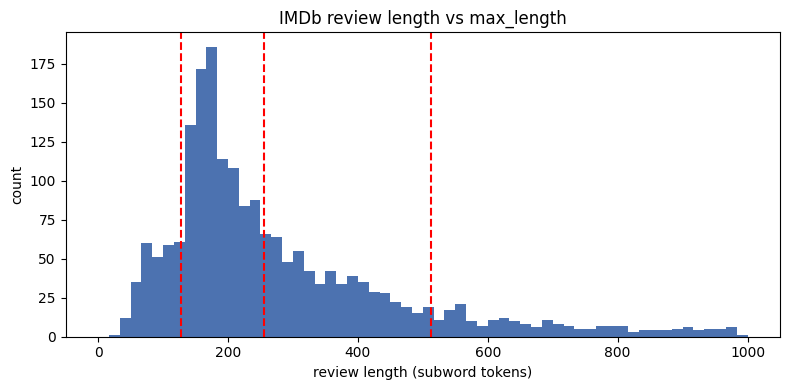

In [3]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(CFG["model_name"])

raw_txt = next(t for t in raw["train"]["text"][:200] if "<br />" in t)
print("raw   :", raw_txt[:160].replace("\n", " "))
print("clean :", clean(raw_txt)[:160])
s = train.text.iloc[0][:200]
print("\nword tokens   :", s.lower().split()[:15])
print("subword tokens:", tok.tokenize(s)[:20])
for w in ["unwatchable", "cinematography", "overacted"]:
    print(f"{w:15s}->", tok.tokenize(w))

lens = np.array([len(x) for x in tok(train.text.tolist()[:2000], add_special_tokens=False)["input_ids"]])
print(f"\nmean tokens={lens.mean():.0f}  median={np.median(lens):.0f}")
for L in (128, 256, 512):
    print(f"reviews longer than {L:3d} tokens: {np.mean(lens > L):.0%}")

plt.figure(figsize=(8, 4)); plt.hist(lens, bins=60, range=(0, 1000), color="#4C72B0")
for L in (128, 256, 512): plt.axvline(L, color="r", ls="--")
plt.xlabel("review length (subword tokens)"); plt.ylabel("count"); plt.title("IMDb review length vs max_length")
plt.tight_layout(); plt.savefig(BACKUP / "length_hist.png", dpi=150); plt.show()

The lengths peak at roughly 170 to 200 tokens and have a long tail past 500. The red lines mark 128, 256 and 512 tokens, so a 128-token window cuts off most reviews, 256 cuts a good share of them and 512 only touches the longest. The exact percentages are printed above.

## A4. Baseline: TF-IDF and logistic regression

Word unigrams or unigrams plus bigrams, with a small grid over the regularisation strength `C`. The best setting on the validation set is kept.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
import joblib

def macro_f1(y, p): return f1_score(y, p, average="macro")

def fit_baseline(texts, y, ngram=(1, 2), C=4.0):
    return make_pipeline(
        TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True, max_features=200_000),
        LogisticRegression(C=C, max_iter=1000)).fit(texts, y)

rows = []
for ng in [(1, 1), (1, 2)]:
    for C in [1.0, 4.0, 16.0]:
        m = fit_baseline(train.text, train.label, ng, C)
        rows.append(dict(ngram=ng, C=C, val_macro_f1=macro_f1(val.label, m.predict(val.text))))
base_abl = pd.DataFrame(rows); display(base_abl)
b = base_abl.sort_values("val_macro_f1").iloc[-1]
BASE_NGRAM, BASE_C = b["ngram"], b["C"]
baseline = fit_baseline(train.text, train.label, BASE_NGRAM, BASE_C)
print("chosen baseline:", BASE_NGRAM, BASE_C, "val macro-F1 =", round(b["val_macro_f1"], 4))

vec, clf = baseline.steps[0][1], baseline.steps[1][1]
fn, coef = np.array(vec.get_feature_names_out()), clf.coef_[0]
o = np.argsort(coef)
print("\nmost negative n-grams:", list(fn[o[:15]]))
print("most positive n-grams:", list(fn[o[-15:]][::-1]))

,ngram,C,val_macro_f1
0,"(1, 1)",1.0,0.858976
1,"(1, 1)",4.0,0.865981
2,"(1, 1)",16.0,0.862997
3,"(1, 2)",1.0,0.856993
4,"(1, 2)",4.0,0.864997
5,"(1, 2)",16.0,0.868999


chosen baseline: (1, 2) 16.0 val macro-F1 = 0.869

most negative n-grams: ['bad', 'worst', 'awful', 'the worst', 'boring', 'waste', 'worse', 'nothing', 'terrible', 'no', 'stupid', 'poor', 'or', 'instead', 'script']
most positive n-grams: ['great', 'excellent', 'perfect', 'very', 'wonderful', 'amazing', 'job', 'brilliant', 'favorite', 'best', 'love', 'especially', 'loved', 'the best', 'this is']


## A5. DistilBERT fine-tuning and ablations

I fine-tune `distilbert-base-uncased` for 2 epochs and train six variants:

1. `max_length` 128, 256 and 512, keeping the start of the review (`head`)
2. at 256 tokens, which part is kept: the start (`head`), the end (`tail`) or the first quarter plus the last three quarters of the window (`head+tail`)
3. at 256 tokens, a frozen encoder (only the classification head is trained) against full fine-tuning

All variants are scored on the validation set, never on the test set. The validation set contains 1,000 reviews, so small differences should be treated cautiously. Each variant uses a single seed.

In [5]:
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup

def encode(texts, max_length=256, strategy="head"):
    raw_ids = tok(list(texts), add_special_tokens=False, truncation=False)["input_ids"]
    budget, out = max_length - 2, []
    for ids in raw_ids:
        if len(ids) > budget:
            if strategy == "head":        ids = ids[:budget]
            elif strategy == "tail":      ids = ids[-budget:]
            elif strategy == "head+tail":
                h = budget // 4;          ids = ids[:h] + ids[-(budget - h):]
            else: raise ValueError(strategy)
        out.append([tok.cls_token_id] + ids + [tok.sep_token_id])
    return out

def collate(batch):
    ids = [b[0] for b in batch]; L = max(len(x) for x in ids)
    inp = torch.full((len(ids), L), tok.pad_token_id); att = torch.zeros((len(ids), L), dtype=torch.long)
    for i, x in enumerate(ids):
        inp[i, :len(x)] = torch.tensor(x); att[i, :len(x)] = 1
    return inp, att, torch.tensor([b[1] for b in batch])

@torch.no_grad()
def predict_proba(model, texts, max_length=256, strategy="head", bs=64):
    model.eval(); dev = next(model.parameters()).device
    enc = encode(texts, max_length, strategy)
    order = np.argsort([len(x) for x in enc]); res = np.zeros((len(enc), 2), dtype=np.float32)
    for i in range(0, len(enc), bs):
        idx = order[i:i + bs]
        inp, att, _ = collate([(enc[j], 0) for j in idx])
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev.type == "cuda")):
            logits = model(input_ids=inp.to(dev), attention_mask=att.to(dev)).logits
        res[idx] = torch.softmax(logits.float(), -1).cpu().numpy()
    return res

def run_experiment(name, max_length=256, strategy="head", freeze=False):
    set_seed()
    enc = encode(train.text, max_length, strategy)
    bs = CFG["batch_size"] if max_length <= 256 else 16
    dl = DataLoader(list(zip(enc, train.label.tolist())), batch_size=bs, shuffle=True, collate_fn=collate)
    model = AutoModelForSequenceClassification.from_pretrained(CFG["model_name"], num_labels=2).to(DEVICE)
    if freeze:
        for p in model.distilbert.parameters(): p.requires_grad = False
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=CFG["lr_frozen"] if freeze else CFG["lr"], weight_decay=0.01)
    total = CFG["epochs"] * len(dl)
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))
    t0 = time.time()
    for _ in range(CFG["epochs"]):
        model.train()
        for inp, att, y in dl:
            inp, att, y = inp.to(DEVICE), att.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                loss = model(input_ids=inp, attention_mask=att, labels=y).loss
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0); scaler.step(opt); scaler.update(); sch.step()
    sec = time.time() - t0
    p = predict_proba(model, val.text, max_length, strategy).argmax(1)
    return model, dict(run=name, max_length=max_length, strategy=strategy, freeze=freeze,
                       val_macro_f1=round(macro_f1(val.label, p), 4),
                       val_acc=round(accuracy_score(val.label, p), 4), train_sec=round(sec))

running len128_head ...


   {'run': 'len128_head', 'max_length': 128, 'strategy': 'head', 'freeze': False, 'val_macro_f1': 0.839, 'val_acc': 0.839, 'train_sec': 28}
running len256_head ...


   {'run': 'len256_head', 'max_length': 256, 'strategy': 'head', 'freeze': False, 'val_macro_f1': 0.892, 'val_acc': 0.892, 'train_sec': 45}
running len512_head ...


   {'run': 'len512_head', 'max_length': 512, 'strategy': 'head', 'freeze': False, 'val_macro_f1': 0.909, 'val_acc': 0.909, 'train_sec': 102}
running len256_tail ...


   {'run': 'len256_tail', 'max_length': 256, 'strategy': 'tail', 'freeze': False, 'val_macro_f1': 0.896, 'val_acc': 0.896, 'train_sec': 47}
running len256_head+tail ...


   {'run': 'len256_head+tail', 'max_length': 256, 'strategy': 'head+tail', 'freeze': False, 'val_macro_f1': 0.896, 'val_acc': 0.896, 'train_sec': 47}
running len256_frozen ...


   {'run': 'len256_frozen', 'max_length': 256, 'strategy': 'head', 'freeze': True, 'val_macro_f1': 0.8479, 'val_acc': 0.848, 'train_sec': 15}


,run,max_length,strategy,freeze,val_macro_f1,val_acc,train_sec
0,len512_head,512,head,False,0.9090,0.909,102
1,len256_tail,256,tail,False,0.8960,0.896,47
2,len256_head+tail,256,head+tail,False,0.8960,0.896,47
3,len256_head,256,head,False,0.8920,0.892,45
4,len256_frozen,256,head,True,0.8479,0.848,15
5,len128_head,128,head,False,0.8390,0.839,28


best config on validation: {'max_length': 512, 'strategy': 'head', 'freeze': False}


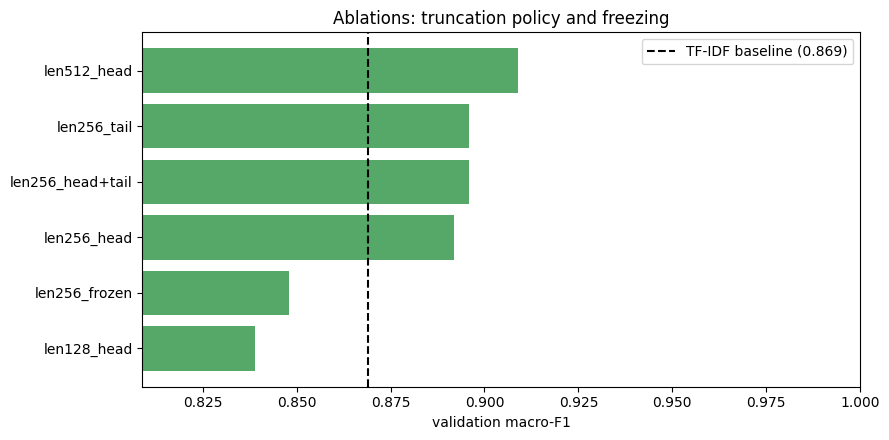

In [6]:
RUNS = [
    dict(name="len128_head",      max_length=128, strategy="head"),
    dict(name="len256_head",      max_length=256, strategy="head"),
    dict(name="len512_head",      max_length=512, strategy="head"),
    dict(name="len256_tail",      max_length=256, strategy="tail"),
    dict(name="len256_head+tail", max_length=256, strategy="head+tail"),
    dict(name="len256_frozen",    max_length=256, strategy="head", freeze=True),
]
ablation_rows, best_row, best_state = [], None, None
for r in RUNS:
    print("running", r["name"], "...", flush=True)
    model, row = run_experiment(**r); ablation_rows.append(row); print("  ", row)
    if best_row is None or row["val_macro_f1"] > best_row["val_macro_f1"]:
        best_row = row; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    del model
    if DEVICE == "cuda": torch.cuda.empty_cache()

abl = pd.DataFrame(ablation_rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(abl)
BEST = dict(max_length=int(best_row["max_length"]), strategy=best_row["strategy"], freeze=bool(best_row["freeze"]))
print("best config on validation:", BEST)

base_val = macro_f1(val.label, baseline.predict(val.text))
plt.figure(figsize=(9, 4.5)); plt.barh(abl.run[::-1], abl.val_macro_f1[::-1], color="#55A868")
plt.axvline(base_val, color="k", ls="--", label=f"TF-IDF baseline ({base_val:.3f})")
plt.xlim(max(0.5, abl.val_macro_f1.min() - 0.03), 1.0); plt.xlabel("validation macro-F1"); plt.legend()
plt.title("Ablations: truncation policy and freezing"); plt.tight_layout()
plt.savefig(BACKUP / "ablation_val.png", dpi=150); plt.show()

### What the ablations show

- **Window size matters most.** At 128 tokens DistilBERT scores about 0.84, which is below the TF-IDF baseline (0.869). At 256 tokens it reaches about 0.89 and at 512 about 0.91. A 128-token window throws away most of a typical review, while TF-IDF sees the whole text.
- **Which part of the review is kept matters much less.** At 256 tokens the start (0.892), the end (0.896) and head+tail (0.896) are within half a point of each other. That is well inside the noise, so I cannot say one is better.
- **Freezing the encoder costs about 4 points** (0.848 frozen against 0.892 fine-tuned at the same window). Training only the classification head was not enough here. The frozen run used a higher learning rate and the same two epochs, so it may be undertrained, but I did not test that.
- **512 tokens had the highest validation score** (about 0.909), roughly 1.7 points above 256. That is borderline given the noise, but it is the best run so I use it as the advanced model. The cost is slower training and slower inference.

## A6. Test results

The test set is used once, with the configuration chosen on validation. The error bars are 95% bootstrap intervals over the 2,000 test reviews.

TF-IDF + LR  macro-F1=0.8665  acc=0.8665  95% CI [0.8520, 0.8810]
DistilBERT   macro-F1=0.9130  acc=0.9130  95% CI [0.9000, 0.9245]

               precision    recall  f1-score   support

         neg      0.902     0.927     0.914      1000
         pos      0.925     0.899     0.912      1000

    accuracy                          0.913      2000
   macro avg      0.913     0.913     0.913      2000
weighted avg      0.913     0.913     0.913      2000



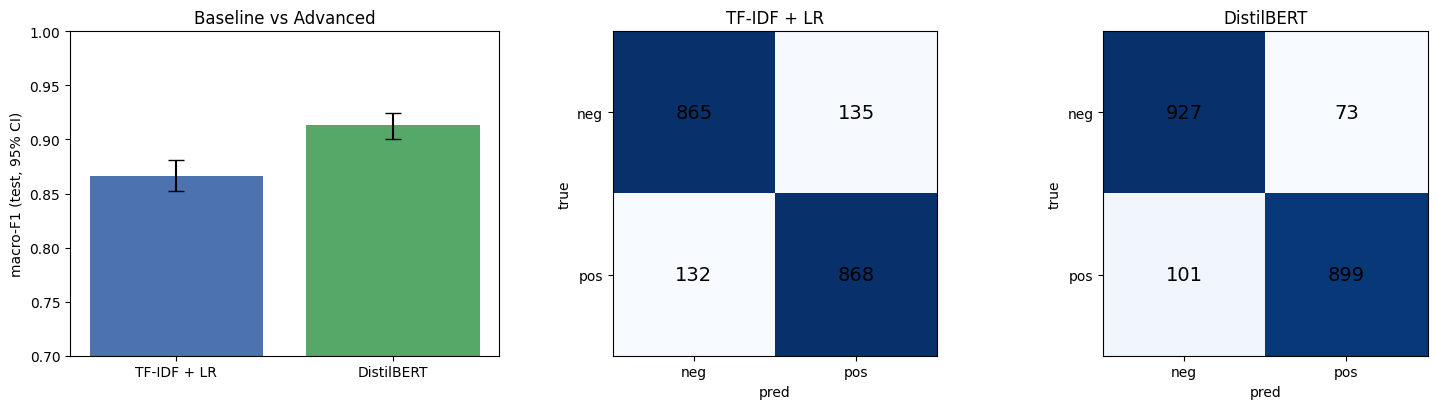

In [7]:
model = AutoModelForSequenceClassification.from_pretrained(CFG["model_name"], num_labels=2)
model.load_state_dict(best_state); model.to(DEVICE).eval()

test["p_base"] = baseline.predict_proba(test.text)[:, 1]
test["p_adv"]  = predict_proba(model, test.text, BEST["max_length"], BEST["strategy"])[:, 1]
test["pb"], test["pa"] = (test.p_base > 0.5).astype(int), (test.p_adv > 0.5).astype(int)

def boot_ci(y, p, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); y, p = np.asarray(y), np.asarray(p)
    v = [macro_f1(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(v, [2.5, 97.5])

TEST = {}
for name, col in [("TF-IDF + LR", "pb"), ("DistilBERT", "pa")]:
    f1, acc, ci = macro_f1(test.label, test[col]), accuracy_score(test.label, test[col]), boot_ci(test.label, test[col])
    TEST[name] = dict(macro_f1=float(f1), acc=float(acc), ci_lo=float(ci[0]), ci_hi=float(ci[1]))
    print(f"{name:12s} macro-F1={f1:.4f}  acc={acc:.4f}  95% CI [{ci[0]:.4f}, {ci[1]:.4f}]")
print("\n", classification_report(test.label, test.pa, target_names=["neg", "pos"], digits=3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
names = list(TEST); vals = [TEST[n]["macro_f1"] for n in names]
errs = [[TEST[n]["macro_f1"] - TEST[n]["ci_lo"] for n in names], [TEST[n]["ci_hi"] - TEST[n]["macro_f1"] for n in names]]
ax[0].bar(names, vals, yerr=errs, color=["#4C72B0", "#55A868"], capsize=6)
ax[0].set_ylim(0.7, 1.0); ax[0].set_ylabel("macro-F1 (test, 95% CI)"); ax[0].set_title("Baseline vs Advanced")
for a, (t, col) in zip(ax[1:], [("TF-IDF + LR", "pb"), ("DistilBERT", "pa")]):
    cm = confusion_matrix(test.label, test[col]); a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center", fontsize=14)
    a.set_xticks([0, 1], ["neg", "pos"]); a.set_yticks([0, 1], ["neg", "pos"]); a.set_title(t); a.set_xlabel("pred"); a.set_ylabel("true")
plt.tight_layout(); plt.savefig(BACKUP / "test_results.png", dpi=150); plt.show()

DistilBERT (512-token window) reaches a test macro-F1 of about 0.913 against about 0.866 for TF-IDF, a gap of roughly 4.7 points. The bootstrap intervals (about 0.900 to 0.924 and 0.852 to 0.881) do not overlap, so the gap looks real.

From the confusion matrices, the baseline makes 267 errors split almost evenly (135 false positives, 132 false negatives). DistilBERT makes 174 errors, but they are not symmetric: 73 false positives and 101 false negatives, so it misses positive reviews somewhat more often than it mislabels negative ones.

## A7. Error analysis

I tag each misclassified review with simple regex cues: truncated by the window, sarcasm phrases, many negations, many contrast words (but, however, although), and short reviews. These tags are rough guesses, so I read the printed examples myself before drawing conclusions. I also look at where the two models disagree and which predictions are borderline.

In [8]:
from collections import Counter
NEG = re.compile(r"(n't|\b(not|no|never|nothing|hardly|barely|without)\b)", re.I)
CONTRAST = re.compile(r"\b(but|however|although|though|despite|yet|nevertheless)\b", re.I)
SARC = re.compile(r"(yeah right|oh great|oh sure|thanks for|what a (great|wonderful|masterpiece)|so[- ]called|ironic|\bnot!)", re.I)

test["ntok"] = [len(x) for x in tok(test.text.tolist(), add_special_tokens=False)["input_ids"]]
def tag_review(text, ntok, max_len):
    t = []
    if ntok > max_len - 2:                  t.append("truncated")
    if SARC.search(text):                   t.append("sarcasm-cue")
    if len(NEG.findall(text)) >= 5:         t.append("negation-heavy")
    if len(CONTRAST.findall(text)) >= 3:    t.append("mixed/contrast")
    if len(text.split()) < 80:              t.append("short")
    return t or ["other"]
test["tags"] = [tag_review(t, n, BEST["max_length"]) for t, n in zip(test.text, test.ntok)]

err = test[test.pa != test.label]
print(f"DistilBERT errors: {len(err)} / {len(test)}   baseline errors: {(test.pb != test.label).sum()}")
cnt = Counter(t for tags in err.tags for t in tags)
base_rate = Counter(t for tags in test.tags for t in tags)
tax = pd.DataFrame({"errors": cnt, "all_test": base_rate}).fillna(0).astype(int)
tax["error_rate"] = (tax.errors / tax.all_test).round(3); display(tax.sort_values("errors", ascending=False))

print("\n12 misclassified reviews (DistilBERT)\n")
for _, r in err.sample(min(12, len(err)), random_state=SEED).iterrows():
    print(f"[true={'pos' if r.label else 'neg'} | P(pos): base={r.p_base:.2f} adv={r.p_adv:.2f} | {r.ntok} tokens | {r.tags}]")
    print("   ", r.text[:350].replace("\n", " "), "...\n")

a_wrong = test[(test.pa != test.label) & (test.pb == test.label)]
b_wrong = test[(test.pb != test.label) & (test.pa == test.label)]
print(f"baseline right, DistilBERT wrong: {len(a_wrong)}   baseline wrong, DistilBERT right: {len(b_wrong)}")
border = test[(test.p_adv - 0.5).abs() < 0.1]
print("borderline DistilBERT predictions (P(pos) within 0.1 of 0.5):", len(border))

DistilBERT errors: 174 / 2000   baseline errors: 267


,errors,all_test,error_rate
mixed/contrast,74,690,0.107
other,71,914,0.078
negation-heavy,60,588,0.102
truncated,32,276,0.116
short,13,162,0.080
sarcasm-cue,3,48,0.062



12 misclassified reviews (DistilBERT)
[true=pos | P(pos): base=0.05 adv=0.01 | 846 tokens | ['truncated', 'negation-heavy', 'mixed/contrast']]
    Un Gatto nel Cervello, or Nightmare Concert as it's more commonly know amongst English speaking audiences, starts as horror film director Lucio Fulci (played by the man himself Lucio Fulci) goes to lunch after filming a very gory & violent scene, however he orders steak & has a horrible vision relating to cannibalism. The grotesque visions, halluci ...

[true=pos | P(pos): base=0.19 adv=0.03 | 260 tokens | ['mixed/contrast']]
    I saw this years ago, and it's entertaining, but not profound. The basic story is of a young man who dreams of Midian, though he's not sure where it is or even if it really exists.  Spoilers Follow: He finally visits it, gets transformed to a Nightbreed creature by being bitten by another one. Then, he has to help the other members of the Nightbree ...

[true=neg | P(pos): base=0.36 adv=0.56 | 54 tokens | ['mixed/c

### Error analysis notes

DistilBERT misclassifies 174 of 2,000 test reviews (8.7%) and the baseline 267. The two models disagree on 267 reviews: the baseline is right and DistilBERT wrong on 87, and the reverse on 180. Only 27 test predictions have P(pos) within 0.1 of 0.5, and 10 of the 12 printed errors have a DistilBERT probability above 0.9 or below 0.1. So the errors are mostly confident ones, not borderline ones.

**Tags.** Error rate by regex tag (the tags overlap, so counts do not add up to 174):

- mixed/contrast: 74 errors in 690 reviews (10.7%), against 7.6% for all other reviews. A chi-square test on these counts gives p of about 0.03.
- truncated (longer than the 512-token window): 32 in 276 (11.6%) against 8.2% for the rest, p of about 0.09. This points the same way but is not clear.
- negation-heavy: 60 in 588 (10.2%) against 8.1%, p of about 0.15, so no clear effect.
- sarcasm-cue: 3 errors in 48 (6.3%). That is too few to say anything, and the regex only catches a handful of stock phrases, so I make no claim about sarcasm.

Six tags were checked, so only the mixed/contrast difference is worth reporting, and even that is modest.

**What the 12 printed reviews show (my own reading of the excerpts).**

- Five are about something other than the quality of the film. Examples are "so bad it's good" reviews of a cult film and a killer-snowman film, a review that praises the show by saying it makes the reviewer "hate" a character, and a reviewer defending a film by listing its criticisms. Negative words push the prediction the wrong way.
- Several are genuinely mixed (for example "entertaining, but not profound", or "disappointing... almost worth seeing") where the verdict is one clause among several.
- One review (846 tokens) is mostly a plot summary of a gory film, and the opinion, if it comes late, is beyond the window.
- One review labelled negative reads as positive in the excerpt ("my only complaint is that it's too short"). That may be label noise. I have not read the full review, so I do not count it as a model error yet.

### Taxonomy and mitigations

| Error type | Evidence | Hypothesis | Mitigation |
|---|---|---|---|
| Opinion about something other than the film (cult "so bad it's good", hating a character, comparing with another film) | 5 of the 12 printed errors; demo row 25 | Negative or positive words are matched without knowing what they refer to; 4,000 training reviews are not enough to learn this | More training data or aspect-aware modelling. Proposed, not tested |
| Mixed or contrast reviews | 74 errors in 690 reviews (10.7% against 7.6%) | Positive and negative clauses compete and the verdict clause is hard to find | Longer fine-tuning or more data. Proposed, not tested |
| Truncated reviews | 32 in 276 (11.6% against 8.2%, not clear) | The verdict often sits at the end and falls outside the window | `head+tail` at 512. At 256 tokens head, tail and head+tail were within noise, and I did not run it at 512, so this stays a hypothesis |
| Overconfident wrong predictions | 10 of 12 printed errors beyond 0.9 or 0.1; only 27 predictions near 0.5 | Fine-tuning makes the model very confident on 4,000 examples | Calibration, such as temperature scaling. Proposed, not tested |
| Possible label noise | One printed review reads positive but is labelled negative | Some IMDb labels come from star ratings that do not match the text | Read the full review and audit a sample of errors by hand |
| Sarcasm | 3 errors in 48 regex matches | Cannot tell: the regex is too crude | Needs a proper sarcasm subset. Future work |


## A8. TF-IDF features and DistilBERT attention on the same review

For one review I show the n-grams that contribute most to the TF-IDF prediction (weight times tf-idf value) next to the tokens the `[CLS]` position attends to most in the last layer, averaged over heads. The example is the first review DistilBERT got wrong in the test sample.

This is defiantly a DVD rental movie. I'm a big fan of the cast members but the storyline never really grabbed me. Don't expect "Oh brother where art thou" in any way shape or form. Funniest part in my opinion is when the war hero explains what happens over in the Argon. Seems like they were trying  ...



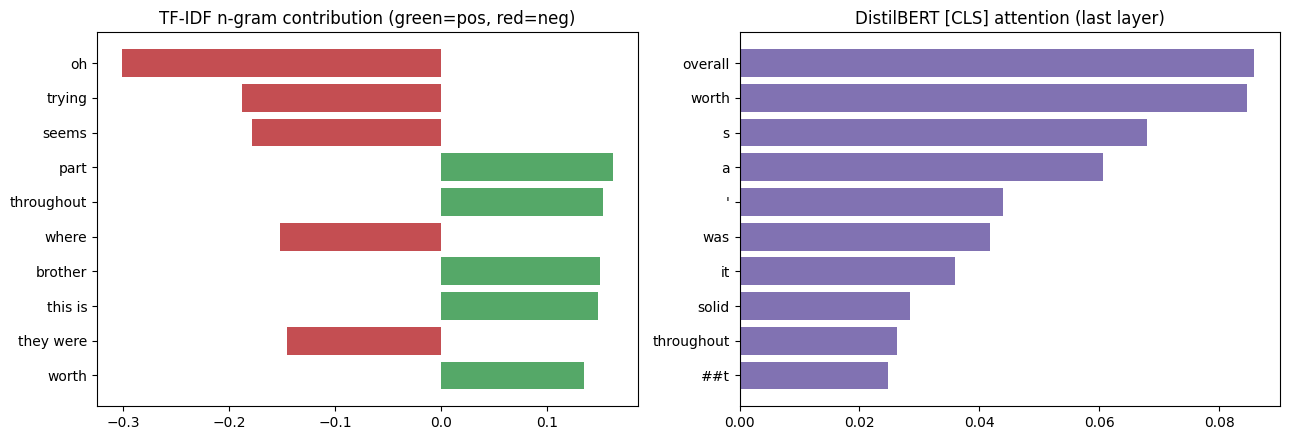

In [9]:
attn_model = AutoModelForSequenceClassification.from_pretrained(CFG["model_name"], num_labels=2, attn_implementation="eager")
attn_model.load_state_dict(best_state); attn_model.to(DEVICE).eval()

def tfidf_top(text, k=10):
    X = vec.transform([text]).tocoo(); c = X.data * coef[X.col]
    idx = np.argsort(-np.abs(c))[:k]; return [(fn[X.col[i]], float(c[i])) for i in idx]

def cls_attention(text, k=10):
    ids = encode([text], BEST["max_length"], BEST["strategy"])[0]
    with torch.no_grad():
        out = attn_model(input_ids=torch.tensor([ids]).to(DEVICE), output_attentions=True)
    a = out.attentions[-1][0].mean(0)[0].float().cpu().numpy()
    toks = tok.convert_ids_to_tokens(ids)
    keep = [i for i, t in enumerate(toks) if t not in ("[CLS]", "[SEP]")]
    top = sorted(keep, key=lambda i: -a[i])[:k]; return [(toks[i], float(a[i])) for i in top]

EXAMPLE = (err.iloc[0] if len(err) else test.iloc[0]).text
print(EXAMPLE[:300], "...\n")
tf, at = tfidf_top(EXAMPLE), cls_attention(EXAMPLE)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh([t for t, _ in tf][::-1], [v for _, v in tf][::-1], color=["#C44E52" if v < 0 else "#55A868" for _, v in tf][::-1])
ax[0].set_title("TF-IDF n-gram contribution (green = pos, red = neg)")
ax[1].barh([t for t, _ in at][::-1], [v for _, v in at][::-1], color="#8172B2"); ax[1].set_title("DistilBERT [CLS] attention (last layer)")
plt.tight_layout(); plt.savefig(BACKUP / "interpretability.png", dpi=150); plt.show()

The two models look at different evidence. TF-IDF is driven by words like "oh", "trying" and "seems" (negative) and "part", "throughout" and "worth" (positive). DistilBERT's attention goes mostly to "overall", "worth" and "solid", and only "worth" and "throughout" appear in both lists. Attention also lands on tokens like "s", "a" and an apostrophe, which carry no sentiment, so it is a rough hint about what the model reads and not a faithful explanation of the prediction.

## A9. Gender-swap probe and augmentation

If a review is rewritten so that only its gendered words change (he and she, actor and actress, man and woman and so on), its sentiment should not change. So any prediction that flips after the swap is unwanted sensitivity. I measure the flip rate on 300 test reviews that contain at least one swappable word, for the baseline, for DistilBERT, and for a baseline retrained on the training data plus gender-swapped copies of it (counterfactual data augmentation).

The swap is a simple word list. "her" always becomes "his", which is not always grammatical, and names are not swapped. I only tested the mitigation on the baseline, not on DistilBERT.

In [10]:
SWAP = {"he":"she","she":"he","him":"her","her":"his","his":"her","himself":"herself","herself":"himself",
        "actor":"actress","actress":"actor","actors":"actresses","actresses":"actors","man":"woman","woman":"man",
        "men":"women","women":"men","boy":"girl","girl":"boy","father":"mother","mother":"father",
        "husband":"wife","wife":"husband","son":"daughter","daughter":"son"}
_pat = re.compile(r"\b(" + "|".join(SWAP) + r")\b", re.I)
def gender_swap(t):
    def rep(m):
        w = m.group(0); s = SWAP[w.lower()]; return s.capitalize() if w[0].isupper() else s
    return _pat.sub(rep, t)

probe = test[test.text.map(lambda t: gender_swap(t) != t)].head(300).copy()
probe["swapped"] = probe.text.map(gender_swap); print("probe size:", len(probe))

def bias_row(name, p_orig, p_swap, f1_val):
    flip = float(np.mean((p_orig > .5) != (p_swap > .5)))
    return dict(model=name, val_macro_f1=round(f1_val, 4), flip_rate=round(flip, 4), mean_abs_dP=round(float(np.mean(np.abs(p_orig - p_swap))), 4))

aug = pd.concat([train[["text", "label"]], train.assign(text=train.text.map(gender_swap))[["text", "label"]]])
baseline_cda = fit_baseline(aug.text, aug.label, BASE_NGRAM, BASE_C)

bias_rows = [
    bias_row("TF-IDF (original)", baseline.predict_proba(probe.text)[:, 1], baseline.predict_proba(probe.swapped)[:, 1], macro_f1(val.label, baseline.predict(val.text))),
    bias_row("TF-IDF + augmentation", baseline_cda.predict_proba(probe.text)[:, 1], baseline_cda.predict_proba(probe.swapped)[:, 1], macro_f1(val.label, baseline_cda.predict(val.text))),
    bias_row("DistilBERT", predict_proba(model, probe.text, BEST["max_length"], BEST["strategy"])[:, 1],
                           predict_proba(model, probe.swapped, BEST["max_length"], BEST["strategy"])[:, 1], float(best_row["val_macro_f1"])),
]
bias_df = pd.DataFrame(bias_rows); display(bias_df)

probe size: 300


,model,val_macro_f1,flip_rate,mean_abs_dP
0,TF-IDF (original),0.869,0.0133,0.0144
1,TF-IDF + augmentation,0.869,0.0033,0.0014
2,DistilBERT,0.909,0.0033,0.0025


### Ethics note

**Licence and source.** Maas et al. (2011), Learning Word Vectors for Sentiment Analysis, ACL-HLT 2011, pp. 142–150. Homepage: http://ai.stanford.edu/~amaas/data/sentiment/. Accessed via Hugging Face (stanfordnlp/imdb); the same corpus is listed in TensorFlow Datasets as imdb_reviews/plain_text. The authors state no formal licence (the Hugging Face card says “other”), so I treat it as research and coursework use only, with attribution, and I do not redistribute it beyond the 120-review demo sample.

**Representativeness.** The reviews are English only, written by self-selected IMDb users, mostly about mainstream films, and strongly polarised because neutral reviews were removed. The models will probably do worse on other domains, other dialects or ambiguous opinions. The reviews contain no personal information about private individuals, but they do name real actors and directors.

**Possible harm.** A sentiment score that shifts with gendered wording could skew any analysis built on top of it.

**Mitigation tested.** Counterfactual data augmentation on the TF-IDF baseline, measured with the probe above.

**Result.** On 300 test reviews with at least one swappable word, the original baseline changed its prediction on 1.33% of them (4 reviews). After augmentation it changed on 0.33% (1 review), the mean change in P(pos) fell from 0.0144 to 0.0014, and validation macro-F1 stayed at 0.869. DistilBERT, with no mitigation, also flipped on 0.33% (1 review). So augmentation helped the baseline without costing accuracy, but 4 flips against 1 is too few to be sure. The probe is a crude word list, it covers only gender, and I did not test augmentation on DistilBERT.

## A10. Save files for the demo

In [11]:
joblib.dump(baseline, ART / "baseline.joblib"); joblib.dump(baseline_cda, ART / "baseline_cda.joblib")
model.save_pretrained(ART / "advanced"); tok.save_pretrained(ART / "advanced")
demo = strat_sample(test, CFG["n_demo"])[["id", "text", "label"]]; demo.to_csv("demo.csv", index=False)
json.dump(dict(model_name=CFG["model_name"], best=BEST, seed=SEED, ablation_lengths=[128, 256]), open(ART / "config.json", "w"), indent=2)
b2 = base_abl.copy(); b2["ngram"] = b2["ngram"].astype(str)
json.dump(dict(ablation=abl.to_dict("records"), baseline_ablation=b2.to_dict("records"), test=TEST, bias=bias_df.to_dict("records")),
          open(ART / "results.json", "w"), indent=2)
with open("requirements.txt", "w") as f:
    for m in (np, pd, torch, sklearn, transformers, datasets, matplotlib, joblib):
        f.write(f"{m.__name__.replace('sklearn', 'scikit-learn')}=={m.__version__}\n")
print(open("requirements.txt").read()); print("saved:", sorted(p.name for p in ART.iterdir()), "demo.csv", demo.shape)

numpy==2.1.3
pandas==3.1.0
torch==2.11.0+cu130
scikit-learn==1.9.1
transformers==5.22.1
datasets==5.1.0
matplotlib==3.10.0
joblib==1.6.0

saved: ['advanced', 'baseline.joblib', 'baseline_cda.joblib', 'config.json', 'results.json'] demo.csv (120, 3)


## A11. Summary

- DistilBERT beats the TF-IDF baseline on the test sample by about 4.7 points of macro-F1 (0.913 against 0.866), and the confidence intervals do not overlap.
- Window size is the biggest factor. With a 128-token window DistilBERT is worse than TF-IDF on validation. It overtakes the baseline at 256 tokens and does best at 512.
- Keeping the start, the end or both ends of the review made no clear difference at 256 tokens.
- Freezing the encoder cost about 4 points.
- Errors are mostly confident ones. Mixed or contrast reviews have a higher error rate (10.7% against 7.6%), and many errors are reviews whose praise or criticism is aimed at something other than the film's quality.
- On the gender-swap probe, augmentation cut the baseline's flip rate from 1.3% to 0.3% (4 reviews to 1) with no loss in validation macro-F1. DistilBERT flipped on 0.3% (1 review). The counts are small.

Limits: one seed per run, a 4,000-review training sample, 2 epochs and no hyperparameter search for DistilBERT. In practice, for long reviews it is worth checking the truncation window before changing the model.

# Part B: live demo

Restart the kernel and run from here down. This part works offline, does no training and only does inference on CPU.

## 1. Setup (versions & seeds)

In [12]:
import os
os.environ["HF_HUB_OFFLINE"] = "1"; os.environ["TRANSFORMERS_OFFLINE"] = "1"; os.environ["TOKENIZERS_PARALLELISM"] = "false"
import time, json, random
T0 = time.time()
import numpy as np, pandas as pd, torch, sklearn, transformers, joblib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
transformers.logging.set_verbosity_error()
SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
for m in (np, pd, torch, sklearn, transformers): print(f"{m.__name__:14s}{m.__version__}")
print("seed =", SEED, "| device = cpu")

numpy         2.1.3
pandas        3.1.0
torch         2.11.0+cu130
sklearn       1.9.1
transformers  5.22.1
seed = 42 | device = cpu


## 2. Load Models & Tokenisers (offline)

In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
ART = Path("artifacts"); CFG = json.load(open(ART / "config.json")); RES = json.load(open(ART / "results.json"))
baseline = joblib.load(ART / "baseline.joblib")
tok = AutoTokenizer.from_pretrained(ART / "advanced")
adv = AutoModelForSequenceClassification.from_pretrained(ART / "advanced").eval()
LABELS = {0: "neg", 1: "pos"}
print("advanced model trained with:", CFG["best"])

advanced model trained with: {'max_length': 512, 'strategy': 'head', 'freeze': False}


## 3. Load Demo Split

In [14]:
demo = pd.read_csv("demo.csv")
print(demo.shape, "| positive rate:", round(demo.label.mean(), 2))

(120, 3) | positive rate: 0.5


## 4. Functions

In [15]:
def encode(texts, max_length, strategy):
    raw = tok(list(texts), add_special_tokens=False, truncation=False)["input_ids"]; budget, out = max_length - 2, []
    for ids in raw:
        if len(ids) > budget:
            if strategy == "head": ids = ids[:budget]
            elif strategy == "tail": ids = ids[-budget:]
            else: h = budget // 4; ids = ids[:h] + ids[-(budget - h):]
        out.append([tok.cls_token_id] + ids + [tok.sep_token_id])
    return out

@torch.inference_mode()
def adv_proba(texts, max_length, strategy, bs=32):
    enc = encode(texts, max_length, strategy); order = np.argsort([len(x) for x in enc]); res = np.zeros((len(enc), 2), dtype=np.float32)
    for i in range(0, len(enc), bs):
        idx = order[i:i + bs]; L = max(len(enc[j]) for j in idx)
        inp = torch.full((len(idx), L), tok.pad_token_id); att = torch.zeros((len(idx), L), dtype=torch.long)
        for r, j in enumerate(idx): inp[r, :len(enc[j])] = torch.tensor(enc[j]); att[r, :len(enc[j])] = 1
        res[idx] = torch.softmax(adv(input_ids=inp, attention_mask=att).logits, -1).numpy()
    return res

def predict_baseline(text):
    p = baseline.predict_proba([text])[0]; k = int(p.argmax()); return LABELS[k], float(p[k])

def predict_advanced(text, max_length=128, strategy=None):
    p = adv_proba([text], max_length, strategy or CFG["best"]["strategy"])[0]; k = int(p.argmax()); return LABELS[k], float(p[k])

def macro_f1(y, p): return f1_score(y, p, average="macro")

## 5. Quick Inference Panel

Five short inputs. The first is positive overall but all three settings call it negative, which gives a clear failure case. The second is a sarcastic review that all three get right. The third is off-distribution (slang and punctuation): DistilBERT is barely confident on it (0.52) while the baseline is at 0.79. The last two are a fairness probe that differs only in "actress" against "actor". Each shows the predicted label and its confidence.

In [16]:
EXEMPLARS = [
    ("failure case (all wrong)", "I expected to hate it, and for the first hour I did. Then the final act reframed everything and I left grinning."),
    ("sarcasm (all correct)", "The plot was predictable and the acting wooden. Great, just what I wanted on a Friday night."),
    ("off-distribution", "gr8 movie!!! lol 10/10 would watch again"),
    ("fairness probe (F)", "The actress delivered a gripping, brilliant performance."),
    ("fairness probe (M)", "The actor delivered a gripping, brilliant performance."),
]
print(f"{'case':24s}| {'baseline':14s}| {'adv@128':14s}| {'adv@256':14s}| text")
print("-" * 100)
for tag, t in EXEMPLARS:
    b, a1, a2 = predict_baseline(t), predict_advanced(t, 128), predict_advanced(t, 256)
    f = lambda r: f"{r[0]} ({r[1]:.2f})"
    print(f"{tag:24s}| {f(b):14s}| {f(a1):14s}| {f(a2):14s}| {t[:45]}")

case                    | baseline      | adv@128       | adv@256       | text
----------------------------------------------------------------------------------------------------
failure case (all wrong)| neg (0.67)    | neg (0.98)    | neg (0.98)    | I expected to hate it, and for the first hour
sarcasm (all correct)   | neg (0.92)    | neg (0.90)    | neg (0.90)    | The plot was predictable and the acting woode
off-distribution        | pos (0.79)    | pos (0.52)    | pos (0.52)    | gr8 movie!!! lol 10/10 would watch again
fairness probe (F)      | pos (0.91)    | pos (0.99)    | pos (0.99)    | The actress delivered a gripping, brilliant p
fairness probe (M)      | pos (0.92)    | pos (0.99)    | pos (0.99)    | The actor delivered a gripping, brilliant per


## 6. Ablation Toggle: max_length 128 and 256

The weights stay fixed; only the inference window changes. This is a small check of the window-size ablation in Part A.

In [17]:
ST = CFG["best"]["strategy"]; texts = demo.text.tolist(); y = demo.label.values
ntok = np.array([len(x) for x in tok(texts, add_special_tokens=False)["input_ids"]])
RESULTS, PREDS = {}, {}
for L in CFG["ablation_lengths"]:
    t = time.time(); p = adv_proba(texts, L, ST).argmax(1); PREDS[L] = p
    RESULTS[L] = dict(macro_f1=macro_f1(y, p), acc=accuracy_score(y, p), sec=time.time() - t, truncated=float(np.mean(ntok > L - 2)))
    print(f"max_length={L:3d}  macro-F1={RESULTS[L]['macro_f1']:.3f}  acc={RESULTS[L]['acc']:.3f}  "
          f"truncated={RESULTS[L]['truncated']:.0%}  time={RESULTS[L]['sec']:.1f}s")
d = RESULTS[256]["macro_f1"] - RESULTS[128]["macro_f1"]
print(f"\nchange in macro-F1 from 128 to 256: {d:+.3f}; predictions changed on {int((PREDS[128] != PREDS[256]).sum())} of {len(y)} reviews")

max_length=128  macro-F1=0.908  acc=0.908  truncated=90%  time=7.2s
max_length=256  macro-F1=0.933  acc=0.933  truncated=38%  time=12.6s

change in macro-F1 from 128 to 256: +0.025; predictions changed on 5 of 120 reviews


On the 120-review demo split, increasing the window from 128 to 256 tokens raised macro-F1 from 0.908 to 0.933, and both DistilBERT settings beat the baseline (0.875). This split is small. On the 1,000-review validation set, the 128-token window scored below the baseline, so the larger validation ablation is the stronger comparison.

## 7. Visuals

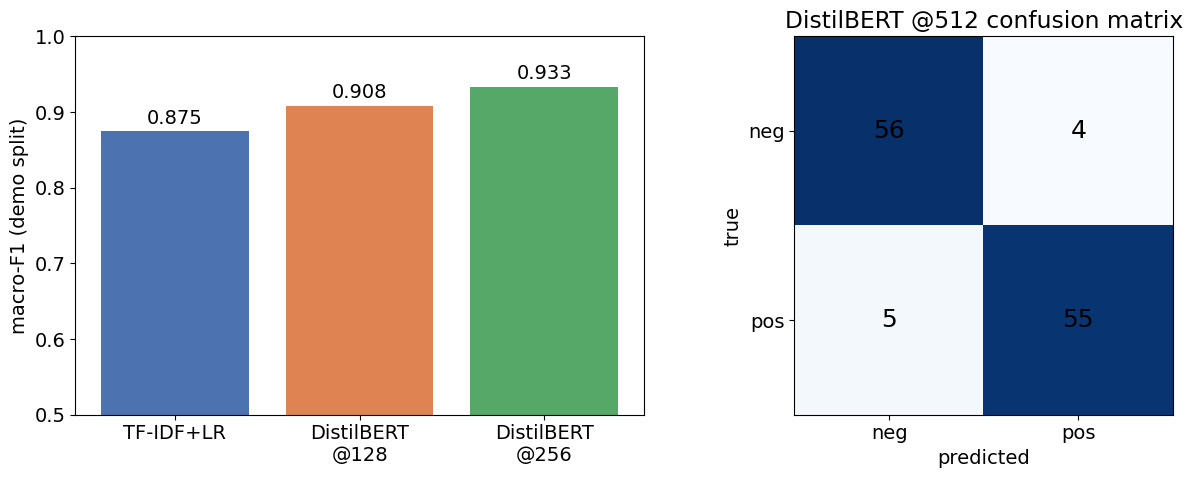

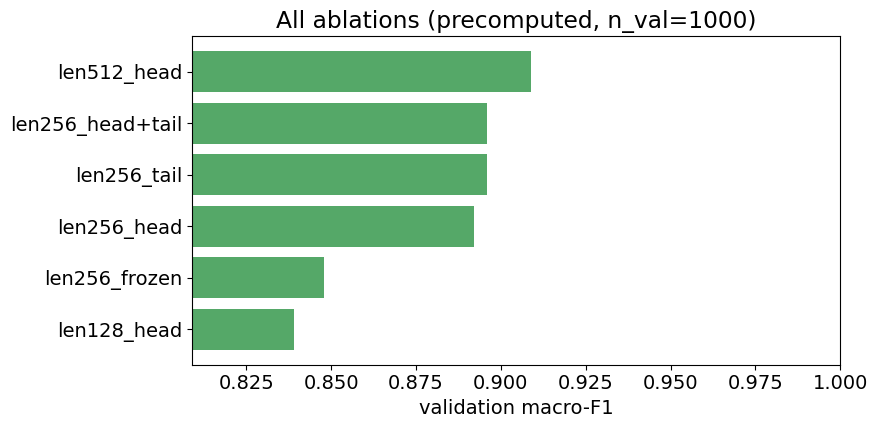

In [18]:
plt.rcParams.update({"font.size": 14})
pb = baseline.predict(texts); base_f1 = macro_f1(y, pb)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
names = ["TF-IDF+LR", "DistilBERT\n@128", "DistilBERT\n@256"]; vals = [base_f1, RESULTS[128]["macro_f1"], RESULTS[256]["macro_f1"]]
ax[0].bar(names, vals, color=["#4C72B0", "#DD8452", "#55A868"]); ax[0].set_ylim(0.5, 1.0); ax[0].set_ylabel("macro-F1 (demo split)")
for i, v in enumerate(vals): ax[0].text(i, v + 0.01, f"{v:.3f}", ha="center")
BL = CFG["best"]["max_length"]; cm = confusion_matrix(y, adv_proba(texts, BL, ST).argmax(1))
ax[1].imshow(cm, cmap="Blues"); ax[1].set_title(f"DistilBERT @{BL} confusion matrix")
for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, v, ha="center", va="center", fontsize=18)
ax[1].set_xticks([0, 1], ["neg", "pos"]); ax[1].set_yticks([0, 1], ["neg", "pos"]); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.tight_layout(); plt.savefig("backup/demo_results.png", dpi=150); plt.show()

ab = pd.DataFrame(RES["ablation"]).sort_values("val_macro_f1")
plt.figure(figsize=(9, 4.5)); plt.barh(ab.run, ab.val_macro_f1, color="#55A868"); plt.xlim(max(0.5, ab.val_macro_f1.min() - 0.03), 1.0)
plt.xlabel("validation macro-F1"); plt.title("All ablations (from Part A, n_val=1000)"); plt.tight_layout(); plt.show()

## 8. Failure Case

In [19]:
adv_pred = adv_proba(texts, BL, ST); ap = adv_pred.argmax(1)
bad = np.where((ap != y) & (pb == y))[0]; bad = bad if len(bad) else np.where(ap != y)[0]
if len(bad):
    i = int(bad[0]); print(f"demo row {i} | true={LABELS[int(y[i])]} | baseline={LABELS[int(pb[i])]} | "
                           f"advanced={LABELS[int(ap[i])]} (P(pos)={adv_pred[i,1]:.2f}) | {ntok[i]} tokens (window {BL})\n")
    print(texts[i][:700], "...")
FAILURE_HYPOTHESIS = "My hypothesis, not tested: the 512-token window covers the whole 173-token review, so truncation is not the cause. The review is negative overall but praises another film (\"enchanting, marvelous\") and ends on \"great waltz scene\" and \"glamorous\", so many of the positive words are not about this film. The baseline gets it right, while DistilBERT is confident and wrong (P(pos)=0.97)."
print("\nwhy it failed:", FAILURE_HYPOTHESIS)

demo row 25 | true=neg | baseline=neg | advanced=pos (P(pos)=0.97) | 173 tokens (window 512)

I feel terribly sorry! Where the Lubitsch-pic was enchanting, marvelous, full of spirit and elegance, this one here is only - colored! Lana looks like 51 (in fact she was 31 at that time, but obviously depressive) and tries to play a shy and dull girlie. Think of Jeanette McDonald, who gave the role of the widow a double-faced depth by "playing" with Count Danilo. That Lana had to play an operetta although unable to sing - crazy! She only sings one song - the title role of an Lehar-operetta, that is really funny! The only really good thing is the great waltz scene at the end: glamorous! And - after watching this scene - have a look at the introducing waltz scene in "Gentlemen Prefer Blondes" ...

why it failed: My hypothesis, not tested: the 512-token window covers the whole 173-token review, so truncation is not the cause. The review is negative overall but praises another film ("enchanting, 

## 9. Ethics Note

The data are IMDb reviews from Maas et al. (2011). The Hugging Face card lists the licence as "other" with no terms given, so I use it for coursework only. The reviews are English, from self-selected IMDb users, mostly about mainstream films, and polarised (no neutral reviews), so the models may not transfer to other domains. A sentiment score that changes with gendered wording could skew downstream analysis. I tested counterfactual data augmentation on the baseline; the baseline's flip rate on 300 gender-swapped test reviews fell from 1.3% to 0.3% (4 reviews to 1) with validation macro-F1 unchanged at 0.869, and DistilBERT is at 0.3% without any mitigation. These counts are small, so the effect is suggestive, not proven. The full table is below.

In [20]:
display(pd.DataFrame(RES["bias"]))
total = time.time() - T0
print(f"\ntotal demo runtime: {total:.1f}s", "(within 60s)" if total < 60 else "(over 60s)")

,model,val_macro_f1,flip_rate,mean_abs_dP
0,TF-IDF (original),0.869,0.0133,0.0144
1,TF-IDF + augmentation,0.869,0.0033,0.0014
2,DistilBERT,0.909,0.0033,0.0025



total demo runtime: 60.7s (over 60s)
